# Test 2 HMM models and recent netMHCII(pan) on 2 blind datasets:

1. Data held out from IEDB19 and not including netMHCIIpan-3.2 peptides
2. WUSTL data minus IEDB19+netMHCIIpan

Two HMM models to train:

1. Train on IEDB19 + netMHCIIpan-3.2 - held out test data (Test 1 set)
2. Train on netMHCIIpan-3.2 data

Alleles to train HMM on for blind dataset 1:

- IAb
- IAd
- IAg7
- IEk
- IAk
- IAs
- IEd
- IAu
- IAq

Alleles to train HMM on for blind dataset 2:

- IAb

In [1]:
from __future__ import print_function, division

import os, sys
import pandas as pd
import numpy as np
import time
import gzip
import mhcnames
import matplotlib.pyplot as plt

from Bio import SeqIO
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from mhctools import NetMHCII, NetMHCIIpan, UnsupportedAllele

import ghmm
import logging
log = logging.getLogger("GHMM")
log.setLevel(logging.CRITICAL)

# log library versions and working dir
from scipy.version import full_version as spversion

print('Python    :', sys.version)
print('Numpy     :', np.__version__)
print("Scipy     :", spversion)
print('Pandas    :', pd.__version__)

print("GHMM:      ", "0.9 (manually tracked)") # no such thing as ghmm.__version__, and not under pip
print('Workdir   :', os.getcwd())

Python    : 2.7.16 |Anaconda, Inc.| (default, Mar 14 2019, 16:24:02) 
[GCC 4.2.1 Compatible Clang 4.0.1 (tags/RELEASE_401/final)]
Numpy     : 1.16.3
Scipy     : 1.2.1
Pandas    : 0.24.2
GHMM:       0.9 (manually tracked)
Workdir   : /Users/ilya/Desktop/mhcbinding/blindtest-nature


In [2]:
# functions

### the following function derives from MHCflurry curation script
### https://github.com/openvax/mhcflurry/blob/pan-experiments/downloads-generation/data_curated/curate.py rev 0fe68ee
# modifications:
# - replaced pandas by pd
# - replaced deprecated .ix by .loc
# - adding support for class II data
# - salvaging data from non-standard class II allele names
# - dropping quantitative measurements with no measurement value
# - adding extra fields (organism, papre title, Pubmed ID)

def load_data_iedb(iedb_csv, mhc_class, include_qualitative=True, include_mass_spec=False):

    QUALITATIVE_TO_AFFINITY_AND_INEQUALITY = {
    "Negative": (5000.0, ">"),
    "Positive": (500.0, "<"),  # used for mass-spec hits
    "Positive-High": (100.0, "<"),
    "Positive-Intermediate": (1000.0, "<"),
    "Positive-Low": (5000.0, "<"),
    }
    QUALITATIVE_TO_AFFINITY = dict(
        (key, value[0]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    QUALITATIVE_TO_INEQUALITY = dict(
        (key, value[1]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())

    EXCLUDE_IEDB_ALLELES = [
        "HLA class I",
        "HLA class II",
    ]

    def normalize_allele_name(s):
        try:
            return mhcnames.normalize_allele_name(s)
        except Exception:
            return "UNKNOWN"
    
    # validate inputs before we go into heavy file loading operation
    assert (mhc_class == "I") | (mhc_class == "II"), "MHC class can be I or II"
    
    iedb_df = pd.read_csv(iedb_csv, skiprows=1, low_memory=False)
    print("Loaded iedb data: %s" % str(iedb_df.shape))

    # Ilya: class II or I
    print("Selecting only class {}".format(mhc_class))
    iedb_df = iedb_df.loc[
        iedb_df["MHC allele class"].str.strip().str.upper() == mhc_class
    ]
    print("New shape: %s" % str(iedb_df.shape))

    print("Dropping known unusuable alleles")
    iedb_df = iedb_df.loc[
        ~iedb_df["Allele Name"].isin(EXCLUDE_IEDB_ALLELES)
    ]
    iedb_df = iedb_df.loc[
        (~iedb_df["Allele Name"].str.contains("mutant")) &
        (~iedb_df["Allele Name"].str.contains("CD1"))
    ]

    iedb_df["allele"] = iedb_df["Allele Name"].map(normalize_allele_name)
    
    # Ilya: manual selection of additional class II data with non-canonical
    # IEDB naming 
    iedb_df.loc[iedb_df["Allele Name"] == "H2-d class II", "allele"] = "H-2-IAd"
    iedb_df.loc[iedb_df["Allele Name"] == "H2-b class II", "allele"] = "H-2-IAb"
    iedb_df.loc[iedb_df["Allele Name"] == "H2-s class II", "allele"] = "H-2-IAs"
    iedb_df.loc[iedb_df["Allele Name"] == "H2-k class II", "allele"] = "H-2-IAk"
    iedb_df.loc[iedb_df["Allele Name"] == "H2-q class II", "allele"] = "H-2-IAq"
    iedb_df.loc[iedb_df["Allele Name"] == "H2-f class II", "allele"] = "H-2-IAf"
    iedb_df.loc[iedb_df["Allele Name"] == "H2-IAg7", "allele"] = "H-2-IAg7"
    iedb_df.loc[iedb_df["Allele Name"] == "H2-IEg7", "allele"] = "H-2-IEg7"
    
    print("Dropping un-parseable alleles: %s" % ", ".join(
        iedb_df.loc[iedb_df.allele == "UNKNOWN"]["Allele Name"].unique()))
    iedb_df = iedb_df.loc[iedb_df.allele != "UNKNOWN"]

    print("IEDB measurements per allele:\n%s" % iedb_df.allele.value_counts())

    quantitative = iedb_df.loc[iedb_df["Units"] == "nM"].copy()
    quantitative["measurement_type"] = "quantitative"
    quantitative["measurement_inequality"] = quantitative[
        "Measurement Inequality"
    ].fillna("=").map(lambda s: {">=": ">", "<=": "<"}.get(s, s))
    print("Quantitative measurements: %d" % len(quantitative))
    
    # Ilya: remove quantitative measurement with no measurement values
    print("Dropping quantitative measurements with no measurement value")
    quantitative.dropna(subset = ["Quantitative measurement"], inplace=True)
    print("Quantitative measurements: %d" % len(quantitative))

    qualitative = iedb_df.loc[iedb_df["Units"] != "nM"].copy()
    qualitative["measurement_type"] = "qualitative"
    print("Qualitative measurements: %d" % len(qualitative))
    if not include_mass_spec:
        qualitative = qualitative.loc[
            (~qualitative["Method/Technique"].str.contains("mass spec"))
        ].copy()

    qualitative["Quantitative measurement"] = (
        qualitative["Qualitative Measure"].map(QUALITATIVE_TO_AFFINITY))
    qualitative["measurement_inequality"] = (
        qualitative["Qualitative Measure"].map(QUALITATIVE_TO_INEQUALITY))

    print("Qualitative measurements (possibly after dropping MS): %d" % (
        len(qualitative)))

    iedb_df = pd.concat(
        (
            ([quantitative]) +
            ([qualitative] if include_qualitative else [])),
        ignore_index=True)

    print("IEDB measurements per allele:\n%s" % iedb_df.allele.value_counts())

    print("Subselecting to valid peptides (dropping peptides with PTMs). Starting with: %d" % len(iedb_df))
    iedb_df["Description"] = iedb_df.Description.str.strip()
    iedb_df = iedb_df.loc[
        iedb_df.Description.str.match("^[ACDEFGHIKLMNPQRSTVWY]+$")
    ]
    print("Now: %d" % len(iedb_df))

    print("Annotating last author and category")
    iedb_df["last_author"] = iedb_df.Authors.map(
        lambda x: (
            x.split(";")[-1]
            .split(",")[-1]
            .split(" ")[-1]
            .strip()
            .replace("*", ""))).values
    iedb_df["category"] = (
        iedb_df["last_author"] + " - " + iedb_df["Method/Technique"]).values

    train_data = pd.DataFrame()
    train_data["peptide"] = iedb_df.Description.values
    train_data["measurement_value"] = iedb_df[
        "Quantitative measurement"
    ].values
    train_data["measurement_source"] = iedb_df.category.values
    train_data["measurement_inequality"] = iedb_df.measurement_inequality.values

    # Ilya: additional fields
    train_data["organism"] = iedb_df["Organism Name"].fillna("UNSPECIFIED").values
    train_data["paper_title"] = iedb_df["Title"].fillna("UNSPECIFIED").values
    train_data["pubmed_id"] = iedb_df["PubMed ID"].fillna(0).astype("int64").values
    
    train_data["allele"] = iedb_df["allele"].values
    train_data["original_allele"] = iedb_df["Allele Name"].values
    train_data["measurement_type"] = iedb_df["measurement_type"].values
    train_data = train_data.drop_duplicates([
        'peptide',
        'measurement_value',
        'measurement_source',
        'measurement_inequality',
        'measurement_type',
        'allele',
        'original_allele'
    ]).reset_index(drop=True)

    return train_data

### End of the function derived from MHCflurry curation script

def load_netMHCIIpan32_full_dset(path):
    """ Load the full netMHCIIpan-3.2 dataset located in the given directory"""

    df_netmhciipan_train = pd.read_csv(
        path + '/train1',
        delim_whitespace = True,
        header           = None,
        names            = ['peptide','log_measurement','original_allele']
    )
    df_netmhciipan_test = pd.read_csv(
        path + '/test1',
        delim_whitespace = True,
        header           = None,
        names            = ['peptide','log_measurement','original_allele']
    )
    df_netmhciipan = pd.concat([df_netmhciipan_train, df_netmhciipan_test])

    # get canonical allele names
    df_netmhciipan['allele'] = df_netmhciipan.original_allele.apply(mhcnames.normalize_allele_name)
    
    return df_netmhciipan

def mhcflurize_netMHCIIpan32(netmhcpaniiDf):
    """ Convert netMHCIIpan-3.2 dataset to MHCflurry structure.

    Convert measurment value from logIC50 to IC50, add necessary fields """
    
    df = netmhcpaniiDf.copy()
    
    # add the necessary columns
    df['measurement_value'] = np.round(50000 ** (1 - df['log_measurement']))
    df['measurement_source'] = 'netMHCIIpan-3.2'
    df['measurement_inequality'] = '='
    df['organism'] = 'UNKNOWN'
    df['paper_title'] = 'UNKNOWN'
    df['pubmed_id'] = 0
    df['measurement_type'] = 'quantitative'
    
    # return without unnecessary fields
    return df.drop(columns = ['log_measurement'])

def mergeDatasets(iedbDf, netmhciipanDf):
    """ Merge IEDB with netMHCIIpan-3.2, gving preference to IEDB data 

    The datasets should both be in MHCflurry-like format """

    iedbDfLocal = iedbDf.copy()
    netmhciipanDfLocal = netmhciipanDf.copy()

    # simply give preference to IEDB data
    iedbDfLocal['allele_peptide'] = iedbDfLocal.allele + '_' + iedbDfLocal.peptide
    netmhciipanDfLocal['allele_peptide'] = netmhciipanDfLocal.allele + '_' + netmhciipanDfLocal.peptide
    netmhciipanUnique = netmhciipanDfLocal[
        ~netmhciipanDfLocal.allele_peptide.isin(iedbDfLocal.allele_peptide)
    ]

    return pd.concat([iedbDfLocal, netmhciipanUnique], sort = 'False')

def assignBindingCategories(mflDataset):
    """Assign binding strength categories and length as separate columns in a MHCflurry format dataset
    
    Take into account not only the value, but also the sign for qualitative measurements.
    In this way measurements with inequality sign "<" and affinity greater than 5000,
    and measurements with inequality sign ">" and affinity less than 5000
    are 'undefined', but normally there should be no measurements like this,
    at least MHCflurry curating script does not create such data when converting IEDB
    qualities into affinities for qualitative measurements.

    Also create an explicit length field.
    """
    
    df = mflDataset.copy()

    # assign an explicit peptide length column
    df['peptide_length'] = df.peptide.str.len()

    # by default non-categorized
    df['binding_category'] = 'undefined'

    # strong binders: IC50 <= 50 nM
    df.loc[
        (df.measurement_inequality != '>') &
        (df.measurement_value <= 50),
        'binding_category'
    ] = 'SB'

    # binders: 50 nM < IC50 <= 500 nM
    df.loc[
        (df.measurement_inequality != '>') &
        (df.measurement_value > 50) & 
        (df.measurement_value <= 500),
        'binding_category'
    ] = 'B'

    # weak binders: 500 nM < IC50 <= 5000 nM
    df.loc[
        (df.measurement_inequality != '>') &
        (df.measurement_value > 500) & 
        (df.measurement_value <= 5000),
        'binding_category'
    ] = 'WB'

    # non-binders: qualitative with affinity greater or equal to 5000,
    # and quantitative with affinity greater than 5000
    df.loc[
        (
            (df.measurement_inequality == '>') &
            (df.measurement_value >= 5000) # greater or equal here, because
        ) |
        (
            (df.measurement_inequality == '=') &
            (df.measurement_value > 5000)
        ),
        'binding_category'
    ] = 'NB'
    
    return df

def readGencodeFasta(filename):
    """ Reads out a Gencode fa.gz with translations, returns a dataframe with
    essential fields """
    
    # read out the translations
    with gzip.open(filename, "r") as fagz:
        proteins = [
            protein for protein in SeqIO.parse(
                fagz,
                'fasta'
            )
        ]
        
    # assert that all fasta ID lines have 8 'fields'
    segmentLengthCounts = pd.Series(
        [len(protein.id.split('|')) for protein in proteins]
    ).value_counts()
    assert (
        (len(segmentLengthCounts) == 1) &
        (segmentLengthCounts.index[0] == 8)
    ), 'Different number of fields in fasta ID lines'
        
    # create a dataframe
    gencodeFastaIdFields = [
        'unknown_id',
        'transcript_id',
        'gene_id',
        'Havana_gene_id',
        'Havana_transcript_id',
        'transcript_name',
        'gene_name',
        'length'
    ]
    # we throw away the lengthy first 5 fields; transcript_name is anyway unique
    dfProteome = pd.DataFrame(
        [protein.id.split('|')[5:8] + [str(protein.seq)] for protein in proteins],
        columns = gencodeFastaIdFields[5:8] + ['sequence'],
    )
    # convert length field to integer
    dfProteome.length = pd.to_numeric(dfProteome.length)
        
    return dfProteome

def getRandomUniformPeptide(proteins, minLength, maxLength):
    """ Does not check validity of inputs for performance reasons! """
    
    # pick a random protein (as a string)
    randomProtein = proteins.sample(1).iloc[0]
    
    # generate random length
    peptideLength = np.random.randint(
        minLength,
        min(len(randomProtein), maxLength) + 1
    )
    
    # generate random starting positions
    peptideStart = np.random.randint(0, len(randomProtein) - peptideLength + 1)
    
    return randomProtein[peptideStart : peptideStart + peptideLength]

def generateUniformDecoyDf(dfProteome, n, minLength, maxLength):
    
    assert (minLength <= maxLength), 'Invalid length range'
    
    # get only proteins of sufficient length
    proteins = dfProteome[dfProteome.length >= minLength].sequence
    
    peptides = []
    for i in range(n):
        # ensure that the peptide does not contain unknown aminoacids
        while True:
            p = getRandomUniformPeptide(proteins, minLength, maxLength)
            if ('U' not in p and 'X' not in p):
                break
            else:
                continue        
        peptides.append(p)
        
    # create the dataframe
    decoyDf = pd.DataFrame(peptides, columns = ['peptide'])
    
    return decoyDf

def generateNonuniformDecoyDf(dfProteome, n, lengths, pmf):

    minLength = min(lengths)
    
    # get only proteins of sufficient length
    proteins = dfProteome[dfProteome.length >= minLength].sequence
    
    peptides = []
    for i in range(n):
        
        # generate random length following the given p.m.f.
        peptideLength = np.random.choice(lengths, p = pmf)
    
        while(True):
            
            # pick a random protein (as a string) not shorter than the length
            randomProtein = proteins.sample(1).iloc[0]
            if (len(randomProtein) < peptideLength):
                continue
                 
            # generate a uniformly random starting position
            peptideStart = np.random.randint(0, len(randomProtein) - peptideLength + 1)
            p = randomProtein[peptideStart : peptideStart + peptideLength]
            
            # ensure that the peptide does not contain unknown aminoacids
            if ('U' not in p and 'X' not in p):
                peptides.append(p)
                break
                
    # create the dataframe
    decoyDf = pd.DataFrame(peptides, columns = ['peptide'])
    
    return decoyDf

def mhclflurizeDecoyDf(decoyDf, allele, source, organism, binding_category):
    
    df = decoyDf.copy()
    
    df['allele'] = mhcnames.normalize_allele_name(allele)
    df['original_allele'] = allele
    df['measurement_value'] = np.nan
    df['measurement_source'] = source
    df['measurement_inequality'] = ''
    df['organism'] = organism
    df['paper_title'] = ''
    df['pubmed_id'] = 0
    df['measurement_type'] = ''
    df['binding_category'] = binding_category
    df['peptide_length'] = df.peptide.str.len()
    
    return df[[
        'allele',
        'peptide',
        'peptide_length',
        'binding_category',
        'measurement_value',
        'measurement_inequality',
        'measurement_type',
        'measurement_source',
        'original_allele',
        'organism',
        'paper_title',
        'pubmed_id'
    ]]

def createTrainTestSplit(
    allele,
    dfAll,
    dfTainted,
    testRelSize,
    trainMinLen,
    trainMaxLen,
    testMinLen,
    testMaxLen
): 

    print('IEDB data: {}, netMHCIIpan-3.2 data: {}'.format(dfAll.shape, dfTainted.shape))

    ### Binders

    binders = dfAll[(dfAll.binding_category == 'B') | (dfAll.binding_category == 'SB')]

    # exclude binders tainted by netMHCIIpan-3.2
    bindersTainted = binders[binders.peptide.isin(dfTainted.peptide)]
    bindersClean = binders[~binders.peptide.isin(dfTainted.peptide)]
    print('Binders: {} ({} tainted, {} clean)'.format(len(binders), len(bindersTainted), len(bindersClean)))

    numTestAvailableB = len(bindersClean)
    numTestNeededB = np.round(len(binders) * testRelSize)
    print('Needed binders for test set: {:.0f}'.format(numTestNeededB))

    if (numTestAvailableB >= numTestNeededB):
        cleanSplitRatioB = numTestNeededB / numTestAvailableB
    else:
        cleanSplitRatioB = 0
    print('Clean split ratio binders: {:.02f}'.format(cleanSplitRatioB))


     ### Non-binders

    nonbinders = dfAll[(dfAll.binding_category == 'WB') | (dfAll.binding_category == 'NB')]

    # exclude non-binders tainted by netMHCIIpan-3.2
    nonbindersTainted = nonbinders[nonbinders.peptide.isin(dfTainted.peptide)]
    nonbindersClean = nonbinders[~nonbinders.peptide.isin(dfTainted.peptide)]
    print('Non-binders: {} ({} tainted, {} clean)'.format(len(nonbinders), len(nonbindersTainted), len(nonbindersClean)))

    numTestAvailableN = len(nonbindersClean)
    numTestNeededN = np.round(len(nonbinders) * testRelSize)
    print('Needed non-binders for test set: {:.0f}'.format(numTestNeededN))

    if (numTestAvailableN >= numTestNeededN):
        cleanSplitRatioN = numTestNeededN / numTestAvailableN
    else:
        cleanSplitRatioN = 0
    print('Clean split ratio non-binders: {:.02f}'.format(cleanSplitRatioN))

    # create splits

    cleanBindersTrain, cleanBindersTest = train_test_split(bindersClean, test_size = cleanSplitRatioB)
    print('Clean binders split: training {}, test {}'.format(len(cleanBindersTrain), len(cleanBindersTest)))
    cleanNonbindersTrain, cleanNonbindersTest = train_test_split(nonbindersClean, test_size = cleanSplitRatioN)
    print('Clean non-binders split: training {}, test {}'.format(len(cleanNonbindersTrain), len(cleanNonbindersTest)))

    bindersTrain = pd.concat([bindersTainted, cleanBindersTrain])
    nonbindersTrain = pd.concat([nonbindersTainted, cleanNonbindersTrain])
    allTrain = pd.concat([bindersTrain, nonbindersTrain])
    print(
        'Training set: {} ({} B, {} NB)'.format(
            len(allTrain),
            len(bindersTrain),
            len(nonbindersTrain)
        )
    )

    # leaving a subset of lengths
    allTrain = allTrain[
        (allTrain.peptide_length >= trainMinLen) &
        (allTrain.peptide_length <= trainMaxLen)
    ]
    print('After keeping lengths {}-{}'.format(trainMinLen, trainMaxLen))
    print(
        'Training set: {} ({} B, {} NB)'.format(
            len(allTrain),
            len(allTrain[(allTrain.binding_category == 'B') | (allTrain.binding_category == 'SB')]),
            len(allTrain[(allTrain.binding_category == 'WB') | (allTrain.binding_category == 'NB')])
        )
    )

    bindersTest = cleanBindersTest.copy()
    nonbindersTest = cleanNonbindersTest.copy()
    allTest = pd.concat([bindersTest, nonbindersTest])
    print(
        'Test set: {} ({} B, {} NB)'.format(
            len(allTest),
            len(bindersTest),
            len(nonbindersTest)
        )
    )

    # leaving a subset of lengths
    allTest = allTest[
        (allTest.peptide_length >= testMinLen) &
        (allTest.peptide_length <= testMaxLen)
    ]
    print('After keeping lengths {}-{}'.format(testMinLen, testMaxLen))
    print(
        'Test set: {} ({} B, {} NB)'.format(
            len(allTest),
            len(allTest[(allTest.binding_category == 'B') | (allTest.binding_category == 'SB')]),
            len(allTest[(allTest.binding_category == 'WB') | (allTest.binding_category == 'NB')])
        )
    )

    # remove intersecting peptides from vtest set
    allTest = allTest[~allTest.peptide.isin(allTrain.peptide)]
    print('After removal of intersection with training set')
    print(
        'Test set: {} ({} B, {} NB)'.format(
            len(allTest),
            len(allTest[(allTest.binding_category == 'B') | (allTest.binding_category == 'SB')]),
            len(allTest[(allTest.binding_category == 'WB') | (allTest.binding_category == 'NB')])
        )
    )

    # drop duplicates from testset
    allTest = allTest.drop_duplicates('peptide')
    print('After removal of duplciates')
    print(
        'Test set: {} ({} B, {} NB)'.format(
            len(allTest),
            len(allTest[(allTest.binding_category == 'B') | (allTest.binding_category == 'SB')]),
            len(allTest[(allTest.binding_category == 'WB') | (allTest.binding_category == 'NB')])
        )
    )

    lbv = len(allTest[(allTest.binding_category == 'B') | (allTest.binding_category == 'SB')])
    lbt = len(allTrain[(allTrain.binding_category == 'B') | (allTrain.binding_category == 'SB')])
    lnv = len(allTest[(allTest.binding_category == 'WB') | (allTest.binding_category == 'NB')])
    lnt = len(allTrain[(allTrain.binding_category == 'WB') | (allTrain.binding_category == 'NB')])

    if ((len(allTrain) + len(allTest)) > 0):
        ratioAll = len(allTest) / (len(allTrain) + len(allTest))
    else:
        ratioAll = np.nan
    if (lbt + lbv > 0):
        ratioBinders = lbv / (lbt + lbv)
    else:
        ratioBinders = np.nan
    if (lnt + lnv > 0):
        ratioNonbinders = lnv / (lnt + lnv)
    else:
        ratioNonbinders = np.nan

    print(
        'Actual validation set relative size: {:.02f} ({:.02f} B, {:.02f} NB)'.format(
            ratioAll,
            ratioBinders,
            ratioNonbinders
        )
    )
    
    return (allTrain, allTest)

# define the amino acids alphabet with the stop emission
AminoAcidsZ = ghmm.Alphabet(ghmm.AminoAcids.listOfCharacters + ['Z'])

def alleleShort(alleleName):
    """ Convert the full allele name into a compressed lower-case one """ 
    return alleleName.translate(None, '-*:').lower()

def randomInitHMMwithSpecialStates(numStates, alphabet):
    """Initialize an HMM

    Create an HMM with a random state and dedicated stop state and emission
    numStates - number of hidden states in the HMM
    alphabet - the alphabet of emissions, of ghmm.Alphabet type,
    should contain X and Z emissions for start and stop
    """
    
    # all states equiprobable as initial, Baum-Welch will adjust
    pi = [1] * numStates
    
    # transition probabilities: all random except for the last state, which does not map into anything,
    # so ghmm will recognize it as the final state
    tT = np.random.rand(numStates, numStates)
    tT[numStates - 1] = np.array([0] * numStates)
    
    # emission probabilities: last state will be emitting only the dedicated stop state 'Z'
    # other options not possible:
    # - if we does not let the last state emit at all (silent state), ghmm.baumWelch
    #   will not work as it does not support silent states
    # - if we leave the random emission pattern for the last state, baumWelch complains
    #   that the state cannot be reached (And so the model is wrong)
    # so we need the dedicated stop state
    # Same for the start state
    tE = np.random.rand(numStates, len(alphabet))
    tE[numStates - 1] = np.zeros(len(AminoAcidsZ))
    tE[numStates - 1][AminoAcidsZ.internal('Z')] = 1
    for i in range(0, numStates - 1):
        tE[i][AminoAcidsZ.internal('Z')] = 0
    
    h = ghmm.HMMFromMatrices(alphabet, ghmm.DiscreteDistribution(alphabet), tT, tE, pi)
    h.normalize()
    return h

def trainHMMs(trainingSet, numStatesBinders, numStatesNonbinders, llCutoff):
    
    binders =    trainingSet[(trainingSet.binding_category ==  'B') | (trainingSet.binding_category == 'SB')]
    nonbinders = trainingSet[(trainingSet.binding_category == 'WB') | (trainingSet.binding_category == 'NB')]
    
    print(
        'Training HMM on {} peptides ({} B, {} NB)'.format(
            len(trainingSet),
            len(binders),
            len(nonbinders)
        )
    )
    
    # convert peptides to ghmm structure
    bindersTrainSS = ghmm.SequenceSet(
        AminoAcidsZ,
        [list(str(p) + 'Z') for p in binders.peptide])
    hmmB = randomInitHMMwithSpecialStates(numStatesBinders, AminoAcidsZ)
    tt0 = time.clock()
    hmmB.baumWelch(bindersTrainSS, loglikelihoodCutoff = llCutoff)
    tt1 = time.clock()
    print('Binders model trained in {} s'.format(tt1 - tt0))
    
    nonbindersTrainSS = ghmm.SequenceSet(
        AminoAcidsZ,
        [list(str(p) + 'Z') for p in nonbinders.peptide])
    hmmN = randomInitHMMwithSpecialStates(numStatesNonbinders, AminoAcidsZ)
    tt0 = time.clock()
    hmmN.baumWelch(nonbindersTrainSS, loglikelihoodCutoff = llCutoff)
    tt1 = time.clock()
    print('Non-binders model trained in {} s'.format(tt1 - tt0))
    
    return (hmmB, hmmN)

def prepareHmmSequenceSets(peptides, stopEmission=True):
    
    t0 = time.clock()
    
    if stopEmission:
        peptideList = [str(p) + 'Z' for p in peptides]
    else:
        peptideList = [str(p) for p in peptides]
    
    # need to split in blocks in case there are more than 1.5M peptides (ghmm limitation)
    ghmmMaxSequencesPerSet = 1500000
    lenPeptides = len(peptides)
    numFullBlocks = lenPeptides // ghmmMaxSequencesPerSet
    lenLastBlock = lenPeptides % ghmmMaxSequencesPerSet
    #print('Total peptides:', lenPeptides)
    #print('Full blocks:', numFullBlocks)
    #print('Peptides in the last block:', lenLastBlock)
    
    sequenceSets = []
    # full blocks (if any)
    for i in range(0, numFullBlocks):
        rangeStart = i * ghmmMaxSequencesPerSet
        rangeEnd = rangeStart + ghmmMaxSequencesPerSet
        #print('Converting block {}, range {}:{}...'.format(i, rangeStart, rangeEnd))
        sequenceBlock = ghmm.SequenceSet(
            AminoAcidsZ,
            [list(p) for p in peptideList[rangeStart:rangeEnd]]
        )
        sequenceSets.append(sequenceBlock)
    # last block
    rangeStart = numFullBlocks * ghmmMaxSequencesPerSet
    rangeEnd = lenPeptides
    if (lenLastBlock > 0):
        #print('Converting last block, range {}:{}...'.format(rangeStart, rangeEnd))
        sequenceBlock = ghmm.SequenceSet(
                AminoAcidsZ,
                [list(p) for p in peptideList[rangeStart:rangeEnd]]
            )
        sequenceSets.append(sequenceBlock)
    #print('Total blocks:', len(sequenceSets))
    t1 = time.clock()
    #print('Splitting and conversion to ghmm structures done in {} s'.format(t1 - t0))
    
    return sequenceSets

def predictHmmPeptidesRaw(hmmModelFile, sequenceSets):
    """Predict -10logp values using a given HMM model for binders and non-binders.

       Results will contain -inf values """

    hmm = ghmm.HMMOpen(hmmModelFile)

    return np.concatenate(
        [-10 * np.array(hmm.loglikelihoods(s)) for s in sequenceSets]
    )

## Create train-test splits

In [11]:
# load and create datasets

iedbDf = load_data_iedb(
    '../datasets/iedb/mhc_ligand_full_20190520.csv',
    'II',
    include_qualitative=True,
    include_mass_spec=True
)
iedbDf = iedbDf[(iedbDf.allele.str.startswith('H-2'))]

netmhciipanFullDf = load_netMHCIIpan32_full_dset('../datasets/netmhciipan-3.2/')
netmhciipanFullDf = mhcflurize_netMHCIIpan32(netmhciipanFullDf)
netmhciipanFullDf = netmhciipanFullDf[(netmhciipanFullDf.allele.str.startswith('H-2'))]
netmhciipanFullDf = assignBindingCategories(netmhciipanFullDf)[[
    'allele',
    'peptide',
    'peptide_length',
    'binding_category',
    'measurement_value',
    'measurement_inequality',
    'measurement_type',
    'measurement_source',
    'original_allele',
    'organism',
    'paper_title',
    'pubmed_id'
]]

# merge datasets
mergedDf = mergeDatasets(iedbDf, netmhciipanFullDf)
mergedDf = assignBindingCategories(mergedDf)[[
    'allele',
    'peptide',
    'peptide_length',
    'binding_category',
    'measurement_value',
    'measurement_inequality',
    'measurement_type',
    'measurement_source',
    'original_allele',
    'organism',
    'paper_title',
    'pubmed_id'
]]

proteomeDf = readGencodeFasta('../datasets/proteome-murine/gencode/gencode.vM21.pc_translations.fa.gz')

Loaded iedb data: (1183960, 100)
Selecting only class II
New shape: (193602, 100)
Dropping known unusuable alleles
Dropping un-parseable alleles: HLA-DR1, HLA-DR15, HLA-DR11, HLA-DR13, HLA-DR7, HLA-DR4, HLA-DR3, HLA-DR8, HLA-DR2, HLA-DR52, HLA-DR53, Mamu-DRB*w2:01, HLA-DP, HLA-DR12, HLA-DRB5, HLA-DR17, HLA-DR14, HLA-DR9, HLA-DR5, RT1-B, HLA-DQ1, Patr-DR1, Patr-DR2, Patr-DR3, Patr-DR4, Patr-DR5, Patr-DR7, Patr-DR8, Patr-DR9, Patr-DR10, Mamu-DR1B, Mamu-DR2, Mamu-DR3A, Mamu-DR4, Mamu-DR6, Mamu-DR7A, Mamu-DR8, HLA-DQ2, HLA-DR6, HLA-DR, HLA-DQ5, HLA-DQ8, HLA-DQ6, HLA-DRB3, HLA-DRB4, HLA-DQ, BoLA-DR, BoLA-DQ, HLA-DRB1, HLA-DQ7, HLA-DQ9, RT1-Bl, RT1-Dl, RT1-Ba, RT1-Bn, RT1-Da, RT1-Dn, RT1-Du, RT1-Bu, HLA-DPw2, BoLA-DRB6, RT11 class II, H2-z/d class II, HLA-DPw4, BF21 class II, BF19 class II, SLA class II
IEDB measurements per allele:
HLA-DRA1*01:01-DRB1*01:01    15655
HLA-DRA1*01:01-DRB1*04:01     7690
HLA-DQA1*02:01-DQB1*02:02     7584
HLA-DQA1*05:05-DQB1*03:01     7441
H-2-IAb              

In [4]:
# List of alleles to generate datasets for:
alleleList = [
    'H-2-IAb',
    'H-2-IAd',
    'H-2-IAg7',
    'H-2-IEk',
    'H-2-IAk',
    'H-2-IAs',
    'H-2-IEd',
    'H-2-IAu',
    'H-2-IAq'
]

testRelSize = 0.12
trainMinLen = 9
trainMaxLen = 32
testMinLen = 9
testMaxLen = 32

In [ ]:
splits = {}

for allele in alleleList:
    
    print('---\nCreating train-test split for ' + allele)

    dfAll = mergedDf[mergedDf.allele == allele]
    dfTainted = netmhciipanFullDf[netmhciipanFullDf.allele == allele]
    
    splits[allele] = createTrainTestSplit(
        allele,
        dfAll,
        dfTainted,
        testRelSize,
        trainMinLen,
        trainMaxLen,
        testMinLen,
        testMaxLen
    )
    
    # generate decoy
    testSet = splits[allele][1]
    numTestBinders = len(
        testSet[
            (testSet.binding_category == 'SB') | (testSet.binding_category == 'B')
        ]
    )

    numDecoyPeptides = numTestBinders * 100
    print('Decoy length to generate: {}'.format(numDecoyPeptides))
    
    # create the pmf over length range, interpolating in the gaps
    lengthsHistogram = dfAll.peptide_length.value_counts().sort_index()
    lengths = [i for i in range(testMinLen, testMaxLen + 1)]
    pmf = np.interp(lengths, lengthsHistogram.index.values, lengthsHistogram.values)
    pmf = pmf / sum(pmf)
    print('Non-uniform decoy lengths p.m.f:')
    for z in zip(lengths, pmf):
        print('{}: {:.02f}'.format(z[0], z[1]))
    
    # get non-uniform decoy
    nonuniformDecoyDf = generateNonuniformDecoyDf(proteomeDf, numDecoyPeptides, lengths, pmf)
    nonuniformDecoyDf = mhclflurizeDecoyDf(nonuniformDecoyDf, allele, 'gencode.vM21', 'Mus musculus', 'DN')
    
    # get uniform decoy
    uniformDecoyDf = generateUniformDecoyDf(proteomeDf, numDecoyPeptides, testMinLen, testMaxLen)
    uniformDecoyDf = mhclflurizeDecoyDf(uniformDecoyDf, allele, 'gencode.vM21', 'Mus musculus', 'DU')

    with pd.HDFStore('splitwithdecoy-{}.h5'.format(alleleShort(allele)), mode='w') as hdf:
        hdf.put('training', splits[allele][0])
        hdf.put('test', splits[allele][1])
        hdf.put('udecoy', uniformDecoyDf)
        hdf.put('ndecoy', nonuniformDecoyDf)

## Train HMMs

In [ ]:
llCutoff = 0.00005
numStatesBinders = 25
numStatesNonbinders = 25

for allele in alleleList:
    print(allele)
    dfTraining = pd.read_hdf('splitwithdecoy-{}.h5'.format(alleleShort(allele)), key = 'training')
    hmmB, hmmN = trainHMMs(dfTraining, numStatesBinders, numStatesNonbinders, llCutoff)
    hmmB.write('models/{}-splitwithdecoy-binders.xml'.format(alleleShort(allele)))
    hmmN.write('models/{}-splitwithdecoy-nonbinders.xml'.format(alleleShort(allele)))

In [ ]:
llCutoff = 0.00005
numStatesBinders = 20
numStatesNonbinders = 20

for allele in alleleList:
    print(allele)
    dfTraining = netmhciipanFullDf[netmhciipanFullDf.allele == allele]
    hmmB, hmmN = trainHMMs(dfTraining, numStatesBinders, numStatesNonbinders, llCutoff)
    hmmB.write('models/{}-netmhc-binders.xml'.format(alleleShort(allele)))
    hmmN.write('models/{}-netmhc-nonbinders.xml'.format(alleleShort(allele)))

## Test HMMs and netMHCII(pan)

In [5]:
testSets = {}

for allele in alleleList:
    
    dfTest = pd.read_hdf('splitwithdecoy-{}.h5'.format(alleleShort(allele)), key = 'test')
    dfUDecoy = pd.read_hdf('splitwithdecoy-{}.h5'.format(alleleShort(allele)), key = 'udecoy')
    dfNDecoy = pd.read_hdf('splitwithdecoy-{}.h5'.format(alleleShort(allele)), key = 'ndecoy')
    dfTest = pd.concat([dfTest, dfUDecoy, dfNDecoy])
    
    binders =    dfTest[(dfTest.binding_category ==  'B') | (dfTest.binding_category == 'SB')]
    nonbinders = dfTest[(dfTest.binding_category == 'WB') | (dfTest.binding_category == 'NB')]
    udecoy = dfTest[(dfTest.binding_category == 'DU')]
    ndecoy = dfTest[(dfTest.binding_category == 'DN')]
    
    print(
        'Test set {}: {} peptides ({} B, {} NB, {} DU, {} DN)'.format(
            allele,
            len(dfTest),
            len(binders),
            len(nonbinders),
            len(udecoy),
            len(ndecoy)
        )
    )
    
    print('Computing HMM predictions')
    
    sequenceSet = prepareHmmSequenceSets(dfTest.peptide)
    
    # make raw predictions (-10logp)
    dfTest['HMM1B'] = predictHmmPeptidesRaw(
        'models/{}-splitwithdecoy-binders.xml'.format(alleleShort(allele)),
        sequenceSet
    )
    dfTest['HMM1N'] = predictHmmPeptidesRaw(
        'models/{}-splitwithdecoy-nonbinders.xml'.format(alleleShort(allele)),
        sequenceSet
    )
    dfTest['HMM2B'] = predictHmmPeptidesRaw(
        'models/{}-netmhc-binders.xml'.format(alleleShort(allele)),
        sequenceSet
    )
    dfTest['HMM2N'] = predictHmmPeptidesRaw(
        'models/{}-netmhc-nonbinders.xml'.format(alleleShort(allele)),
        sequenceSet
    )
    
    # normalize by length, replace infs by a large value, and take deltas
    columnsHMM =  ['HMM1B', 'HMM1N', 'HMM2B', 'HMM2N']
    dfTest.loc[:, columnsHMM] = dfTest.loc[:, columnsHMM].div(dfTest.peptide_length, axis=0)
    dfTest = dfTest.replace(np.inf, 10000.0)
    dfTest['HMM1D'] = dfTest['HMM1B'] - dfTest['HMM1N']
    dfTest['HMM2D'] = dfTest['HMM2B'] - dfTest['HMM2N']
    
    for predictorClass in [NetMHCII, NetMHCIIpan]:
        predictorName = predictorClass.__name__
        try:
            # initialize
            predictor = predictorClass(alleles=allele)
            # run
            print('Running {} for {}'.format(predictorName, predictor.alleles))
            predictions = predictor.predict_peptides_dataframe([str(p) for p in dfTest.peptide])
            # drop duplicates
            predictions = predictions.drop_duplicates(
                subset = ['peptide'],
                keep = 'first'
            )[['peptide', 'affinity', 'percentile_rank']]
            # merge into the original dataframe
            dfTest = dfTest.merge(
                predictions,
                on  = 'peptide',
                validate = 'many_to_one' # this to ensure that we give deduped values
            ).rename(
                columns = {
                    'affinity'        : predictorName + '_IC50',
                    'percentile_rank' : predictorName + '_PR'
                }
            )
        except UnsupportedAllele:
            print('{} not supported by {}'.format(allele, predictorName))
            dfTest[predictorName + '_IC50'] = np.nan
            dfTest[predictorName + '_PR'] = np.nan
        except mhcnames.AlleleParseError:
            print('{} not recognized by mhcnames'.format(allele))
            dfTest[predictorName + '_IC50'] = np.nan
            dfTest[predictorName + '_PR'] = np.nan     

    # merge with orginal dataframe
    testSets[allele] = dfTest

Test set H-2-IAb: 111478 peptides (554 B, 124 NB, 55400 DU, 55400 DN)
Computing HMM predictions
Running NetMHCII for ['H-2-IAb']
Running NetMHCIIpan for ['H-2-IAb']
Test set H-2-IAd: 100158 peptides (498 B, 60 NB, 49800 DU, 49800 DN)
Computing HMM predictions
Running NetMHCII for ['H-2-IAd']
Running NetMHCIIpan for ['H-2-IAd']
Test set H-2-IAg7: 5864 peptides (29 B, 35 NB, 2900 DU, 2900 DN)
Computing HMM predictions
H-2-IAg7 not supported by NetMHCII
H-2-IAg7 not supported by NetMHCIIpan
Test set H-2-IEk: 3226 peptides (16 B, 10 NB, 1600 DU, 1600 DN)
Computing HMM predictions
Running NetMHCII for ['H-2-IEk']
Running NetMHCIIpan for ['H-2-IEk']
Test set H-2-IAk: 2437 peptides (12 B, 25 NB, 1200 DU, 1200 DN)
Computing HMM predictions
Running NetMHCII for ['H-2-IAk']
Running NetMHCIIpan for ['H-2-IAk']
Test set H-2-IAs: 2233 peptides (11 B, 22 NB, 1100 DU, 1100 DN)
Computing HMM predictions
Running NetMHCII for ['H-2-IAs']
Running NetMHCIIpan for ['H-2-IAs']
Test set H-2-IEd: 1643 peptide

In [6]:
testSets['H-2-IAg7'].head()

,allele,peptide,peptide_length,binding_category,measurement_value,measurement_inequality,measurement_type,measurement_source,original_allele,organism,...,HMM1B,HMM1N,HMM2B,HMM2N,HMM1D,HMM2D,NetMHCII_IC50,NetMHCII_PR,NetMHCIIpan_IC50,NetMHCIIpan_PR
5558,H-2-IAg7,AVRNAKAAVEEGIVAG,16,B,380.0,=,quantitative,Adorini - purified MHC/competitive/fluorescence,H2-IAg7,Mycobacterium tuberculosis,...,28.461105,26.538578,32.765849,33.758178,1.922527,-0.992329,NaN,NaN,NaN,NaN
98144,H-2-IAg7,DAAKNQLTSNPEN,13,B,500.0,<,qualitative,Unanue - cellular MHC/mass spectrometry,H2-IAg7,Mus musculus,...,34.575751,33.563100,32.657718,33.114605,1.012651,-0.456888,NaN,NaN,NaN,NaN
98646,H-2-IAg7,IPAFKIGLRALQEATY,16,B,500.0,<,qualitative,Rammensee - cellular MHC/mass spectrometry,H2-IAg7,Mus musculus,...,26.652176,30.842590,32.754378,33.096271,-4.190415,-0.341892,NaN,NaN,NaN,NaN
98111,H-2-IAg7,GTSKESAMKTYVEKVDE,17,B,500.0,<,qualitative,Unanue - cellular MHC/mass spectrometry,H2-IAg7,Mus musculus,...,31.122224,30.019948,32.398008,32.566801,1.102276,-0.168793,NaN,NaN,NaN,NaN
87048,H-2-IAg7,GFFYTPMSRRE,11,B,500.0,<,qualitative,Harrison - purified MHC/competitive/fluorescence,H2-IAg7,Mus musculus,...,35.968696,37.817430,33.231473,33.236591,-1.848734,-0.005118,NaN,NaN,NaN,NaN


## Analyze and visualize results
### Uniform vs non-uniform decoy

In [7]:
models = [
    'HMM1B',
    'HMM2B',
    #'HMM1D',
    #'HMM2D',
    #'NetMHCII_IC50',
    'NetMHCII_PR',
    #'NetMHCIIpan_IC50',
    'NetMHCIIpan_PR'
]

aurocs = {}
for allele in alleleList:
    testSet = testSets[allele]
    
    # evaluate with real non-binders
    #testSet = testSet[testSet.binding_category != 'D'].copy()
    
    # evaluate with decoy
    testSet = testSet[
        (testSet.binding_category == 'SB') |
        (testSet.binding_category == 'B') |
        (testSet.binding_category == 'DU')
    ].copy()
    
    testSet['binder'] = (testSet.binding_category == 'B') | (testSet.binding_category == 'SB')
    auroc = {}
    for model in models:
        try:
            auroc[model] = roc_auc_score(~testSet.binder, testSet[model])
        except ValueError:
            auroc[model] = np.nan
    aurocs[allele] = auroc

dfAurocs = pd.DataFrame(aurocs)
dfAurocs

,H-2-IAb,H-2-IAd,H-2-IAg7,H-2-IAk,H-2-IAq,H-2-IAs,H-2-IAu,H-2-IEd,H-2-IEk
HMM1B,0.934530,0.929125,0.860333,0.868403,0.5000,0.843884,0.888025,0.874687,0.751328
HMM2B,0.691066,0.601863,0.352342,0.500000,0.4600,0.595537,0.555556,0.550469,0.487832
NetMHCII_PR,0.781897,0.613138,NaN,0.823056,NaN,0.624421,0.815556,0.620156,0.701328
NetMHCIIpan_PR,0.757691,0.574070,NaN,0.662674,0.6325,0.694793,0.667654,0.724375,0.797793


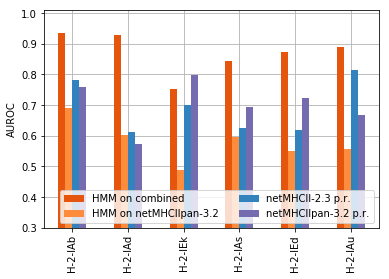

In [10]:
from matplotlib import cm

aurocsToPlot = dfAurocs[[
    'H-2-IAb',
    'H-2-IAd',
    'H-2-IEk',
    'H-2-IAs',
    'H-2-IEd',
    'H-2-IAu'
]].T.rename(
    columns = {
        'HMM1B' : 'HMM on combined',
        'HMM2B' : 'HMM on netMHCIIpan-3.2',
        'NetMHCII_PR' : 'netMHCII-2.3 p.r.',
        'NetMHCIIpan_PR' : 'netMHCIIpan-3.2 p.r.'
    }
)
fooColors = [
    cm.tab20c.colors[4],
    cm.tab20c.colors[5],
    #cm.tab20c.colors[1],
    cm.tab20c.colors[0],
    #cm.tab20c.colors[13],
    cm.tab20c.colors[12]
]

aurocsToPlot.plot(kind = 'bar', figsize=(6,4), color = fooColors, zorder=2)
plt.ylim([0.3,1.01])
plt.grid(zorder=1)
plt.ylabel('AUROC')
plt.legend(loc='lower right', ncol = 2);